In [ ]:
# Customer Segmentation Analysis using RFM and K-Means

## Objective
'''
To segment customers based on their purchasing behaviour using
RFM analysis and K-Means clustering, helping businesses develop
targeted marketing strategies.
'''

'\nTo segment customers based on their purchasing behaviour using\nRFM analysis and K-Means clustering, helping businesses develop\ntargeted marketing strategies.\n'

In [ ]:
## Create a code cell
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
## Step 3 : Load Your dataset

In [ ]:
df = pd.read_csv('retail_sales_dataset.csv')

In [ ]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,24-11-2023,CUST001,Male,34,Beauty,3,50,150
1,2,27-02-2023,CUST002,Female,26,Clothing,2,500,1000
2,3,13-01-2023,CUST003,Male,50,Electronics,1,30,30
3,4,21-05-2023,CUST004,Male,37,Clothing,1,500,500
4,5,06-05-2023,CUST005,Male,30,Beauty,2,50,100


In [ ]:
## Step 4: Inspect the Dataset

In [ ]:
print("Shape:", df.shape)

Shape: (1000, 9)


In [ ]:
df.info()        ##cheacking missing value

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Customer ID'].nunique()

1000

In [ ]:
## Step 5: Clean the data

In [ ]:
df = df.drop_duplicates()

In [ ]:
df['Date'] =pd.to_datetime(df['Date'])   ## convert the date

In [ ]:
df.dtypes

,0
Transaction ID,int64
Date,datetime64[ns]
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64


In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [ ]:
## step 6: Check for Inconsistent Data

In [ ]:
print("Negative Total Amount")
print((df['Total Amount']<0).sum())

print("Zero TOtal Amount:")
print((df['Total Amount']==0).sum())

Negative Total Amount
0
Zero TOtal Amount:
0


In [ ]:
print("Neagative Quantity:")
print((df['Quantity']<0).sum())

Neagative Quantity:
0


In [ ]:
### Data Cleaning Observation
'''
The dataset was checked for missing values, duplicate records,
and inconsistent numerical values. Invalid records were removed
where necessary before performing customer segmentation.
'''

'\nThe dataset was checked for missing values, duplicate records,\nand inconsistent numerical values. Invalid records were removed\nwhere necessary before performing customer segmentation.\n'

In [ ]:
## Step 7: Understand RFM Analysis

In [ ]:
## step 8: Create a Reference Date

In [ ]:
reference_date = df['Date'].max() + pd.Timedelta(days=1)
print(reference_date)

2024-01-02 00:00:00


In [ ]:
## Step 9: Cretae RFM Table

In [ ]:
rfm = df.groupby('Customer ID').agg({
    'Date': lambda x: (reference_date - x.max()).days,
    'Transaction ID': 'count',
    'Total Amount': 'sum'
})

In [ ]:
rfm.rename(columns={
    'Date': 'Recency',
    'Transaction ID': 'Frequency',
    'Total Amount': 'Monetary'
}, inplace=True)

In [ ]:
rfm.head()   ## View It

,Recency,Frequency,Monetary
Customer ID,,,
CUST001,39,1,150
CUST002,309,1,1000
CUST003,354,1,30
CUST004,226,1,500
CUST005,241,1,100


In [ ]:
## Step 10: Descriptive Statistics

In [ ]:
## Avg purchase Value
average_purchase_value = df['Total Amount'].mean()

print("Average Purchase Value:", average_purchase_value)

Average Purchase Value: 456.0


In [ ]:
## Avg purchase Frequency
average_purchase_frequency = rfm['Frequency'].mean()

print("Average Purchase Frequency:", average_purchase_frequency)

Average Purchase Frequency: 1.0


In [ ]:
rfm['CLV'] = rfm['Monetary']

In [ ]:
average_clv = rfm['CLV'].mean()

print("Average Customer Lifetime Value:", average_clv)

Average Customer Lifetime Value: 456.0


In [ ]:
### Note on CLV
'''
Since the dataset does not contain customer lifespan, profit margin,
or acquisition cost information, total customer monetary value is
used as a simplified Customer Lifetime Value (CLV) proxy.
'''

'\nSince the dataset does not contain customer lifespan, profit margin,\nor acquisition cost information, total customer monetary value is\nused as a simplified Customer Lifetime Value (CLV) proxy.\n'

In [ ]:
## Step 11: Analyze RFM Statistics

In [ ]:
rfm[['Recency', 'Frequency', 'Monetary', 'CLV']].describe()

,Recency,Frequency,Monetary,CLV
count,1000.000000,1000.0,1000.000000,1000.000000
mean,182.982000,1.0,456.000000,456.000000
std,105.276773,0.0,559.997632,559.997632
min,1.000000,1.0,25.000000,25.000000
25%,90.000000,1.0,60.000000,60.000000
50%,186.500000,1.0,135.000000,135.000000
75%,269.000000,1.0,900.000000,900.000000
max,366.000000,1.0,2000.000000,2000.000000


In [ ]:
print("Average Recency:", rfm['Recency'].mean())
print("Average Frequency:", rfm['Frequency'].mean())
print("Average Monetary Value:", rfm['Monetary'].mean())

Average Recency: 182.982
Average Frequency: 1.0
Average Monetary Value: 456.0


In [ ]:
## Step 12: Select Featues for Clustering

In [ ]:
features = rfm[['Recency', 'Frequency', 'Monetary']]

In [ ]:
features.head()

,Recency,Frequency,Monetary
Customer ID,,,
CUST001,39,1,150
CUST002,309,1,1000
CUST003,354,1,30
CUST004,226,1,500
CUST005,241,1,100


In [ ]:
## Step 13: Check feature Distribution

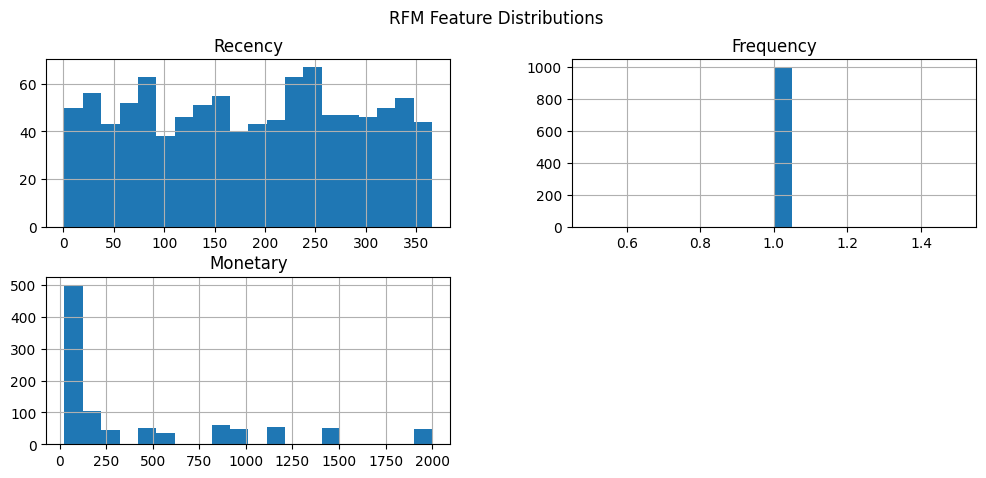

In [ ]:
features.hist(
    figsize=(12, 5),
    bins=20
)

plt.suptitle('RFM Feature Distributions')
plt.show()

In [ ]:
## Step 14: Standardise the Data

In [ ]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(features)

In [ ]:
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary']
)

rfm_scaled_df.head()

,Recency,Frequency,Monetary
0,-1.368336,0.0,-0.546704
1,1.197615,0.0,0.971919
2,1.625274,0.0,-0.761098
3,0.408823,0.0,0.078611
4,0.551375,0.0,-0.636035


In [ ]:
## Step 15: Elbow Method

In [ ]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)

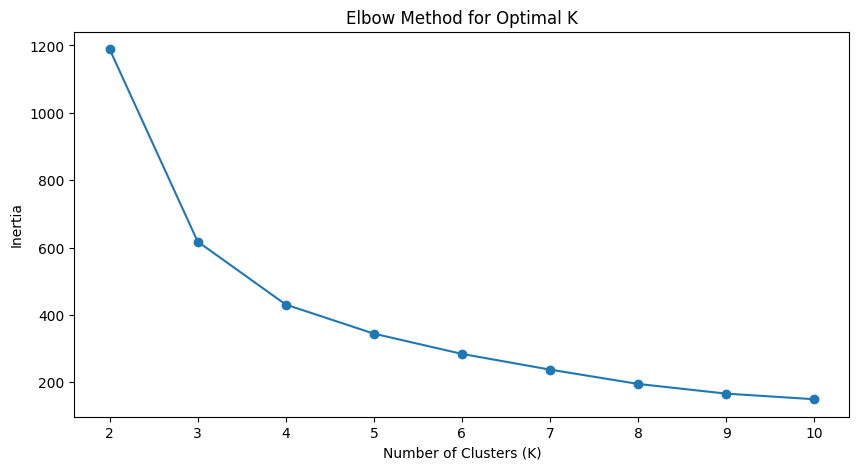

In [ ]:
## plot
plt.figure(figsize=(10, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.show()

In [ ]:
## Step 16: Understand the Elbow Graph

In [ ]:
optimal_k = 4

In [ ]:
## Step 17: Apply K_Means

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

In [ ]:
rfm.head()

,Recency,Frequency,Monetary,CLV,Cluster
Customer ID,,,,,
CUST001,39,1,150,150,1
CUST002,309,1,1000,1000,0
CUST003,354,1,30,30,2
CUST004,226,1,500,500,2
CUST005,241,1,100,100,2


In [ ]:
## Step 18: Count Customer in Each Cluster

In [ ]:
rfm['Cluster'].value_counts().sort_index()

,count
Cluster,
0,140
1,370
2,366
3,124


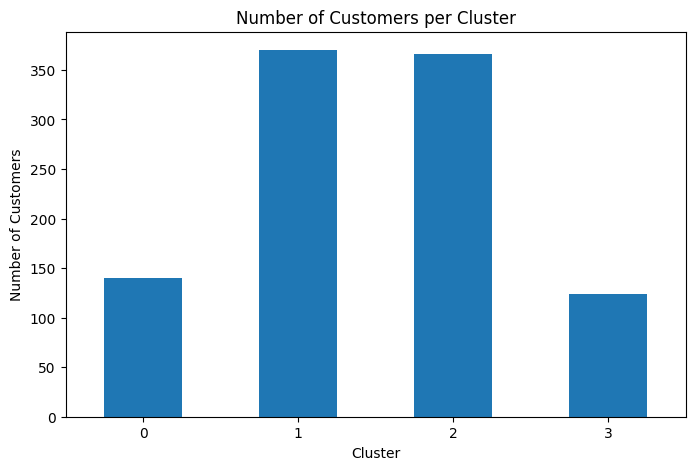

In [ ]:
cluster_counts = rfm['Cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

cluster_counts.plot(kind='bar')

plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

In [ ]:
## Step 19: Profile Each Cluster

In [ ]:
cluster_profile = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary', 'CLV']
].mean()

cluster_profile

,Recency,Frequency,Monetary,CLV
Cluster,,,,
0,270.521429,1.0,1283.571429,1283.571429
1,92.116216,1.0,159.770270,159.770270
2,274.573770,1.0,148.319672,148.319672
3,84.935484,1.0,1313.709677,1313.709677


In [ ]:
## Step 20: Scatter plot Feature Combination 1

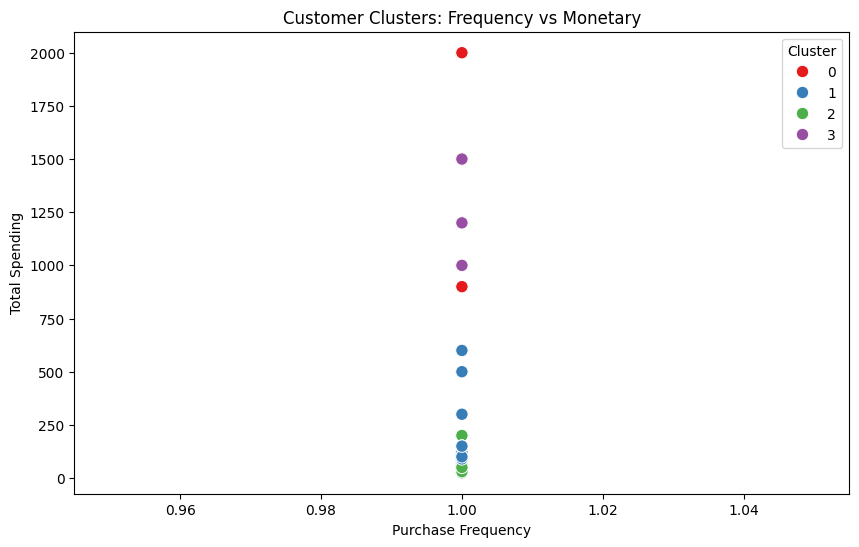

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set1',
    s=80
)

plt.title('Customer Clusters: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending')
plt.show()

In [ ]:
## Step 21: Scatter plot Feature Combination 2

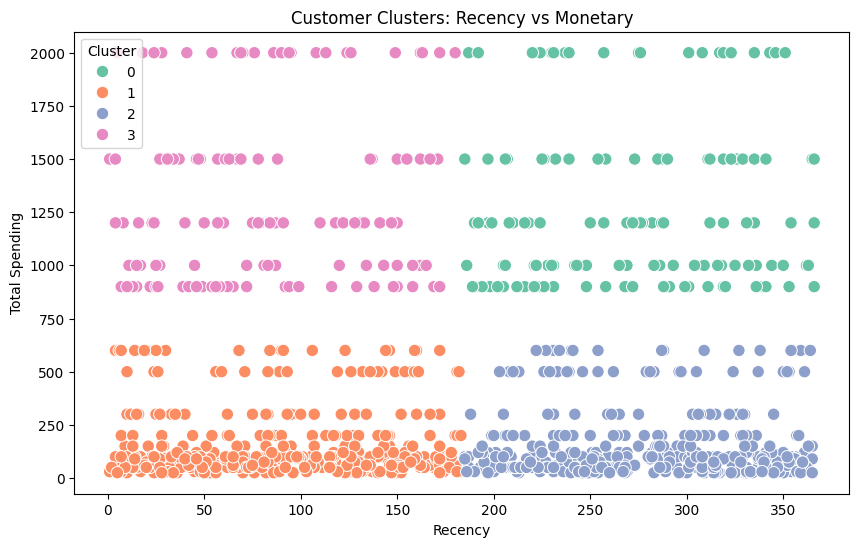

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    s=80
)

plt.title('Customer Clusters: Recency vs Monetary')
plt.xlabel('Recency')
plt.ylabel('Total Spending')
plt.show()

In [ ]:
### Observation
'''
The scatter plot shows that customers are divided into distinct
groups based on purchase frequency and monetary value. Customers
with higher frequency and spending represent valuable segments
for targeted retention strategies.
'''

'\nThe scatter plot shows that customers are divided into distinct\ngroups based on purchase frequency and monetary value. Customers\nwith higher frequency and spending represent valuable segments\nfor targeted retention strategies.\n'

In [ ]:
# Conclusion
'''
RFM analysis and K-Means clustering were used to segment customers
according to their purchasing behaviour. The analysis identified
different customer groups based on recency, frequency, and monetary
value.

These segments can help the business create targeted marketing
strategies such as loyalty rewards, personalized offers,
cross-selling, and customer re-engagement campaigns.
'''

'\nRFM analysis and K-Means clustering were used to segment customers\naccording to their purchasing behaviour. The analysis identified\ndifferent customer groups based on recency, frequency, and monetary\nvalue.\n\nThese segments can help the business create targeted marketing\nstrategies such as loyalty rewards, personalized offers,\ncross-selling, and customer re-engagement campaigns.\n'